In [1]:
import glob
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
path = '/sto4/data/Intermediate/VolMIP/piControl/'
models = ['CanESM5', 'GISS-E2-1-G','MPI-ESM1-2-LR', 'MIROC-ES2L', 'UKESM1-0-LL']
plotdir = '/sto0/user/Kperny/VolMIP_stratosphere/plots/'
nao = {}
nino34 = {}
for model in models:
        nao[model] = xr.open_dataset(glob.glob(path + model + '/piControl_' + model + '_NAO_djf_*.nc')[0]).zg.values
        nino34[model] = xr.open_dataset(glob.glob(path + model + '/piControl_' + model + '_Nino34_djf_*.nc')[0]).tos.values

/tmp/ipykernel_732511/1635610669.py:12: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  nao[model] = xr.open_dataset(glob.glob(path + model + '/piControl_' + model + '_NAO_djf_*.nc')[0]).zg.values
/tmp/ipykernel_732511/1635610669.py:13: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  nino34[model] = xr.open_dataset(glob.glob(path + model + '/piControl_' + model + '_Nino34_djf_*.nc')[0]).tos.values
/tmp/ipykernel_732511/1635610669.py:12: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects inste

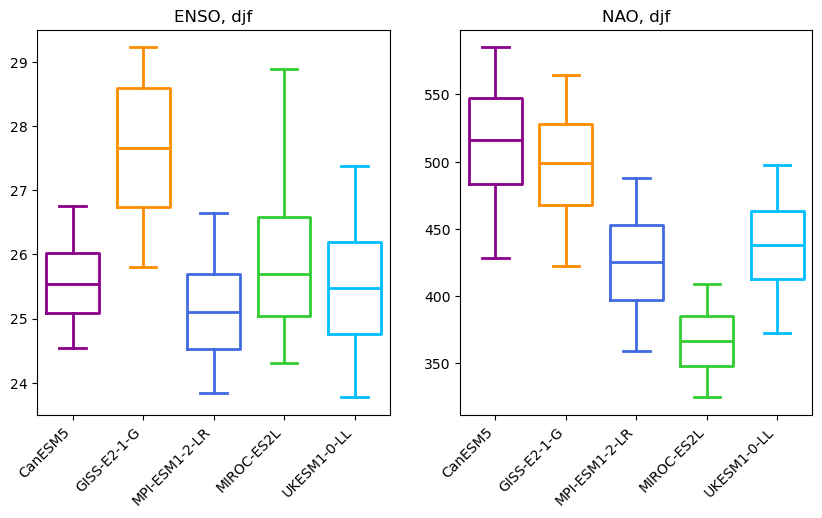

In [2]:
fig, ax = plt.subplots(1,2, figsize=(10,5))
colors = ['darkmagenta', 'darkorange', 'royalblue', 'limegreen', 'deepskyblue']

for i, model in enumerate(models):
    ax[0].boxplot(nino34[model], positions=np.array([i]), whis=(5,95), widths=0.75, showfliers=False,
                boxprops=dict(color=colors[i],linewidth=2), whiskerprops=dict(color=colors[i],linewidth=2),
                capprops=dict(color=colors[i],linewidth=2), medianprops=dict(color=colors[i],linewidth=2))
    ax[1].boxplot(nao[model], positions=np.array([i]), whis=(5,95), widths=0.75, showfliers=False,
                boxprops=dict(color=colors[i],linewidth=2), whiskerprops=dict(color=colors[i],linewidth=2),
                capprops=dict(color=colors[i],linewidth=2), medianprops=dict(color=colors[i],linewidth=2))

ax[0].set_xticklabels(models)
ax[1].set_xticklabels(models)
plt.setp( ax[0].xaxis.get_majorticklabels(), rotation=45, horizontalalignment='right')
plt.setp( ax[1].xaxis.get_majorticklabels(), rotation=45, horizontalalignment='right')
ax[0].set_title('ENSO, djf')
ax[1].set_title('NAO, djf')

plt.savefig(plotdir + 'test_nao_nino-index_piControl.png', bbox_inches='tight', dpi=200)